## MLP TRAINING

**Mục tiêu:** trình bày cấu trúc 92–64–32–12, huấn luyện đủ 100 epoch, log training loss và validation loss để theo dõi hội tụ, sau đó lưu trọng số tại epoch cuối. Validation chỉ dùng theo dõi, không cập nhật trọng số.

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, time
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'processed'
REPORTS = ROOT / 'reports' / '05_mlp_training'
RESULTS = ROOT / 'models'
(REPORTS / 'figures').mkdir(parents=True, exist_ok=True)
(REPORTS / 'tables').mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
TARGET = 'Attack_type'


### 1. Nạp Train và Validation

In [9]:
train=pd.read_csv(DATA/'mlp_train.csv');val=pd.read_csv(DATA/'mlp_validation.csv')
assert train.columns.equals(val.columns) and TARGET in train
X_train=train.drop(columns=[TARGET]).to_numpy(dtype=np.float32)
y_train=train[TARGET].to_numpy(dtype=np.int64)
X_val=val.drop(columns=[TARGET]).to_numpy(dtype=np.float32)
y_val=val[TARGET].to_numpy(dtype=np.int64)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
classes=np.unique(y_train)
print('Train:',X_train.shape,'Validation:',X_val.shape,'Classes:',classes.tolist())

Train: (82536, 92) Validation: (17686, 92) Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


### 2. Kiến trúc và thuật toán tối ưu
MLPClassifier: kiến trúc 92 → 64 → 32 → 12 gồm hai lớp ẩn (64, 32), ReLU, Adam, alpha=0.0001, learning_rate_init=0.001, batch_size=512, early_stopping=False. partial_fit thực hiện một epoch mỗi lần gọi. Log loss trên Train từ model.loss_; validation cross-entropy được tính độc lập để theo dõi. Huấn luyện cố định đủ 100 epoch và lưu trọng số cuối cùng.

In [10]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss
model=MLPClassifier(hidden_layer_sizes=(64,32),activation='relu',solver='adam',alpha=1e-4,
    batch_size=512,learning_rate_init=0.001,early_stopping=False,max_iter=100,
    random_state=42,shuffle=True)
print(model)

MLPClassifier(batch_size=512, hidden_layer_sizes=(64, 32), max_iter=100,
              random_state=42)


### 3. Huấn luyện và in log từng epoch
Mỗi epoch thực hiện lan truyền xuôi, tính loss, lan truyền ngược và cập nhật trọng số bằng Adam. Validation loss chỉ được tính sau epoch. Cấu hình max_epochs=100, mô hình được lưu ở epoch cuối.

In [11]:
max_epochs=100;history=[]
start=time.perf_counter()
for epoch in range(1,max_epochs+1):
    model.partial_fit(X_train,y_train,classes=classes)
    train_loss=float(model.loss_)
    val_proba=model.predict_proba(X_val)
    val_loss=float(log_loss(y_val,val_proba,labels=classes))
    elapsed=time.perf_counter()-start
    history.append({'epoch':epoch,'train_loss':train_loss,'validation_loss':val_loss,'elapsed_seconds':elapsed})
    print(f'Epoch {epoch:02d}/{max_epochs} | train_loss={train_loss:.6f} | val_loss={val_loss:.6f} | elapsed={elapsed:.1f}s',flush=True)
history=pd.DataFrame(history)
print('\nFULL EPOCH LOG (100/100):')
print(history.to_string(index=False,formatters={'epoch':'{:03d}'.format,'train_loss':'{:.6f}'.format,'validation_loss':'{:.6f}'.format,'elapsed_seconds':'{:.1f}'.format}))
history.to_csv(REPORTS/'tables'/'mlp_training_history.csv',index=False)
print('FINISHED | epochs:',len(history),'| final validation loss:',round(history.validation_loss.iloc[-1],6),'| time:',round(time.perf_counter()-start,2),'s')


Epoch 01/100 | train_loss=0.437162 | val_loss=0.093149 | elapsed=1.1s
Epoch 02/100 | train_loss=0.070125 | val_loss=0.059215 | elapsed=2.2s
Epoch 03/100 | train_loss=0.050916 | val_loss=0.048691 | elapsed=3.2s
Epoch 04/100 | train_loss=0.042099 | val_loss=0.041678 | elapsed=4.3s
Epoch 05/100 | train_loss=0.035691 | val_loss=0.036541 | elapsed=5.3s
Epoch 06/100 | train_loss=0.030986 | val_loss=0.031871 | elapsed=6.2s
Epoch 07/100 | train_loss=0.027317 | val_loss=0.029363 | elapsed=7.0s
Epoch 08/100 | train_loss=0.024321 | val_loss=0.027079 | elapsed=7.9s
Epoch 09/100 | train_loss=0.022077 | val_loss=0.025236 | elapsed=8.8s
Epoch 10/100 | train_loss=0.020073 | val_loss=0.023842 | elapsed=9.8s
Epoch 11/100 | train_loss=0.018474 | val_loss=0.022917 | elapsed=10.6s
Epoch 12/100 | train_loss=0.017280 | val_loss=0.022373 | elapsed=11.5s
Epoch 13/100 | train_loss=0.016144 | val_loss=0.021414 | elapsed=12.4s
Epoch 14/100 | train_loss=0.015416 | val_loss=0.021234 | elapsed=13.3s
Epoch 15/100 | t

### 4. Vẽ đường cong hội tụ
Đường cong train loss và validation loss phản ánh quá trình tối ưu.

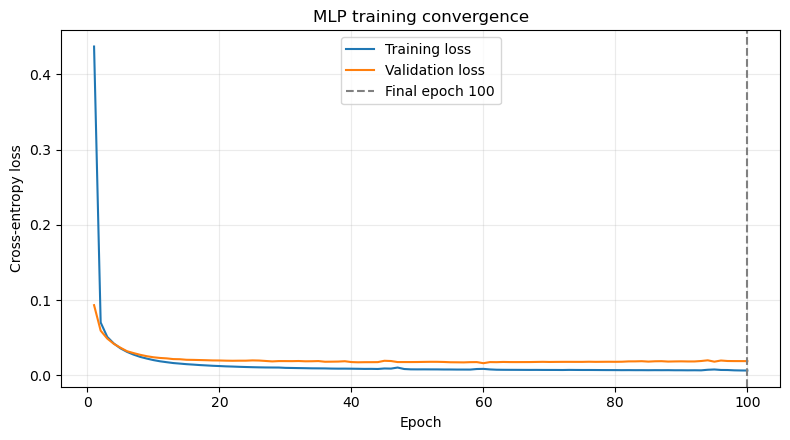

Architecture: 92 -> 64 32 -> 12
Number of weight matrices: 3 | parameter count: 8428


In [12]:
fig,ax=plt.subplots(figsize=(8,4.5));ax.plot(history.epoch,history.train_loss,label='Training loss');ax.plot(history.epoch,history.validation_loss,label='Validation loss');ax.axvline(max_epochs,linestyle='--',color='gray',label=f'Final epoch {max_epochs}');ax.set(xlabel='Epoch',ylabel='Cross-entropy loss',title='MLP training convergence');ax.legend();ax.grid(alpha=.25);fig.tight_layout();fig.savefig(REPORTS/'figures'/'mlp_loss_curve.png',dpi=160);plt.show()
print('Architecture:',model.n_features_in_, '->',*model.hidden_layer_sizes,'->',model.n_outputs_)
print('Number of weight matrices:',len(model.coefs_),'| parameter count:',sum(a.size for a in model.coefs_)+sum(a.size for a in model.intercepts_))

### 5. Lưu và nạp lại mô hình


In [13]:
path=RESULTS/'mlp_baseline.joblib';joblib.dump(model,path)
reloaded=joblib.load(path)
assert np.allclose(model.predict_proba(X_val[:10]),reloaded.predict_proba(X_val[:10]))
print('PASS: model reloaded; file:',path,'| bytes:',path.stat().st_size)

PASS: model reloaded; file: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4\models\mlp_baseline.joblib | bytes: 145120
